# Channel-pair (dyad) sampling

A recording with $M$ channels has $D = M(M-1)/2$ unordered channel pairs (dyads). `compute_pairs` evaluates every SPI on $b \le D$ of them, the same dyads for every SPI and both directions of each, instead of all $D$. The quantity of interest downstream is the SPI–SPI vector $\mathbf{z}$: for each pair of SPIs, the Pearson correlation of their values across ordered channel pairs. Sampling replaces $\mathbf{z}$ by an estimate $\hat{\mathbf{z}}$ from $2b$ ordered pairs.

In [1]:
import json, sys, time, warnings
from pathlib import Path
import numpy as np, pandas as pd
warnings.simplefilter("ignore")

BENCH = Path("../../bench/pair_sampling"); sys.path.insert(0, str(BENCH))
import validate as V
from pyspi.calculator import Calculator, sample_dyads

plt = V.figure_style(backend=None)
plt.rcParams["figure.dpi"] = 110
RESULTS, GADI = BENCH / "results", BENCH / "results" / "gadi-smoke"

## 1. The call

Seven statistics on a sparse VAR(1), $M=20$ ($D=190$), $T=500$. `evaluated on` says whether an SPI was computed on the sampled dyads only, or on every channel and then indexed (a covariance or a spectral matrix is fitted on all channels at once; it is never refitted on two).

In [2]:
x = V.var_series(M=20, T=500, seed=0)
calc = Calculator(dataset=x, config="select.yaml", verbose=False)
calc.compute(progress=False)
dense = {k: calc.table[k].to_numpy(float) for k in calc.spis}

values = calc.compute_pairs(n_pairs=40, seed=1, progress=False)      # (n_spis, b, 2)
i, j = calc.pairs.T
pd.DataFrame([{"SPI": k, "evaluated on": calc.sampling["evaluation"][k],
               "max |sampled - dense|": np.abs(v - np.stack([dense[k][i, j], dense[k][j, i]], 1)).max()}
              for k, v in zip(calc.spis, values)])

,SPI,evaluated on,max |sampled - dense|
0,cov_EmpiricalCovariance,dense,0.0
1,xcorr_max_sig-True,pairs,0.0
2,dcorr,pairs,0.0
3,dtw_constraint-sakoe-chiba_radius-auto,pairs,0.0
4,mi_kraskov_NN-4,pairs,0.0
5,te_kraskov_NN-4_k-1_kt-1_l-1_lt-1,pairs,0.0
6,psi_multitaper_mean_fs-1_fmin-0_fmax-0-5,dense,0.0


In [3]:
{k: v for k, v in calc.sampling.items() if k != "evaluation"}

{'n_processes': 20,
 'n_dyads': 190,
 'n_pairs': 40,
 'source': 'sampled',
 'seed': 1,
 'pairs_sha256': '3ec99aae2072fa969b4a9dd3e4856ed383193e01d49469073023b1bb477c62de',
 'computation_version': '3.0.0.r8',
 'n_jobs': 1}

Top: the full matrix. Bottom: the entries a 40-dyad sample holds (both directions of each dyad; grey is not computed).

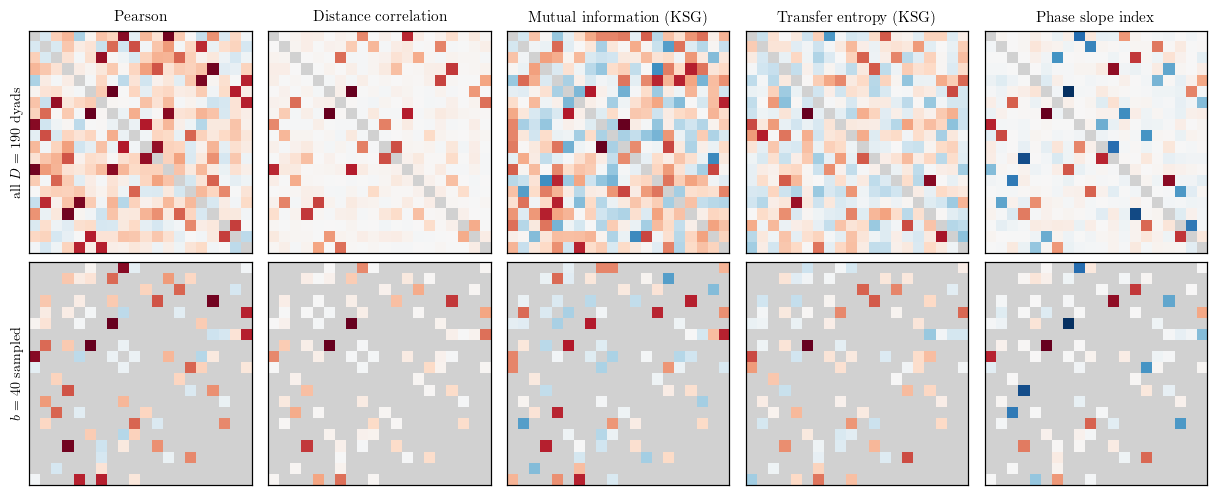

In [4]:
show = ["cov_EmpiricalCovariance", "dcorr", "mi_kraskov_NN-4",
        "te_kraskov_NN-4_k-1_kt-1_l-1_lt-1", "psi_multitaper_mean_fs-1_fmin-0_fmax-0-5"]
titles = ["Pearson", "Distance correlation", "Mutual information (KSG)",
          "Transfer entropy (KSG)", "Phase slope index"]
keys = list(calc.spis)
fig, axes = plt.subplots(2, 5, figsize=(11, 4.4))
for col, (k, title) in enumerate(zip(show, titles)):
    S = dense[k].copy(); np.fill_diagonal(S, np.nan)
    sampled = np.full_like(S, np.nan)
    sampled[i, j], sampled[j, i] = values[keys.index(k)].T
    lim = np.nanmax(np.abs(S))
    signed = np.nanmin(S) < 0
    cmap = plt.get_cmap("RdBu_r" if signed else "viridis").copy(); cmap.set_bad(".82")
    kw = dict(cmap=cmap, vmin=-lim if signed else np.nanmin(S), vmax=lim)
    for ax, A in zip(axes[:, col], (S, sampled)):
        ax.imshow(A, **kw); ax.set(xticks=[], yticks=[])
        for s in ax.spines.values(): s.set_visible(True)
    axes[0, col].set_title(title)
axes[0, 0].set_ylabel(r"all $D=190$ dyads"); axes[1, 0].set_ylabel(r"$b=40$ sampled")
plt.show()

## 2. Convergence of $\hat{\mathbf{z}}$

All 41,616 coordinates of $\mathbf{z}$ from `benchmarked_p90` (289 SPIs). Each curve is the median over 128 random nested samples drawn from a fully computed recording; the last point is the census. MEG: four recordings at each of $M=64, 100, 243$, $T=1000$.

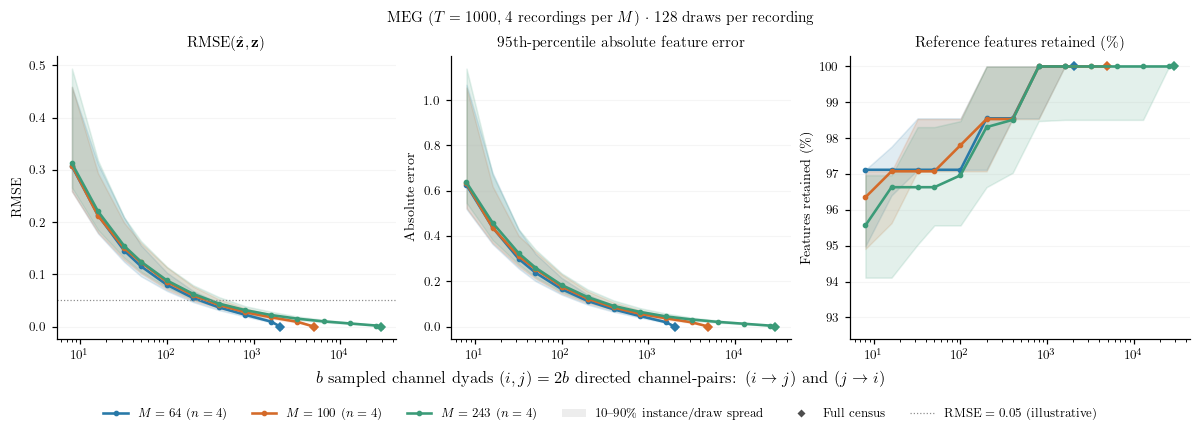

In [5]:
local = pd.read_csv(RESULTS / "local-draws.csv")
meg = pd.read_csv(RESULTS / "meg-draws.csv.gz")
V.whole_vector_figure(plt, meg, None, r"MEG ($T=1000$, 4 recordings per $M$) $\cdot$ 128 draws per recording")
plt.show()

The same for the $M=20$ VAR(1). Red circles are not masked draws but actual `compute_pairs` extractions (nested prefixes of six runs): the sampled extraction and masking the full table give the same $\hat{\mathbf{z}}$.

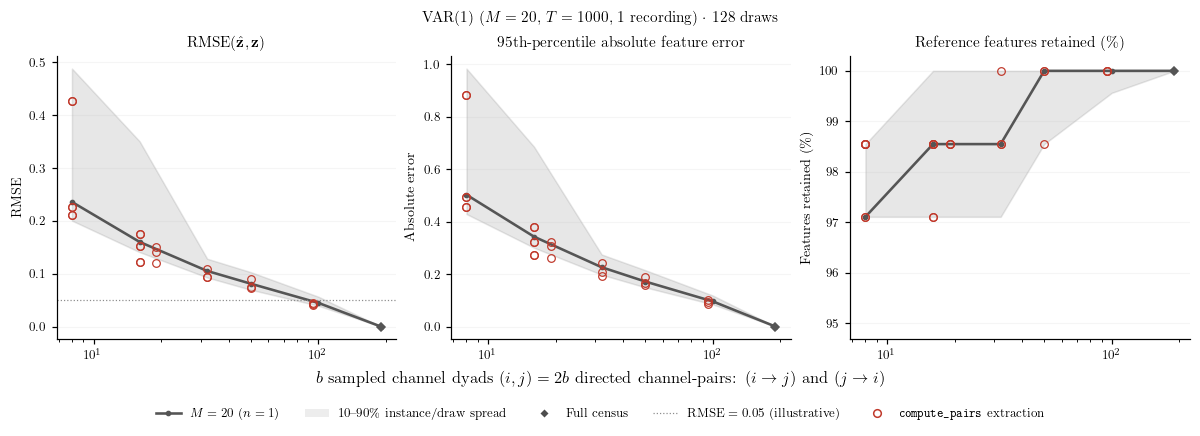

In [6]:
V.whole_vector_figure(plt, local, None, r"VAR(1) ($M=20$, $T=1000$, 1 recording) $\cdot$ 128 draws",
                      extracted=pd.read_csv(RESULTS / "local-extracted.csv"))
plt.show()

## 3. Individual coordinates

Twenty-four SPI–SPI coordinates chosen by what the statistics mean, for one MEG recording at $M=243$ and at $M=64$. Dashed: exact value. Line: median of 128 draws. Band: 2.5–97.5% of draws. Coordinates near $\pm1$ converge fastest; a coordinate whose exact value is undefined stays undefined.

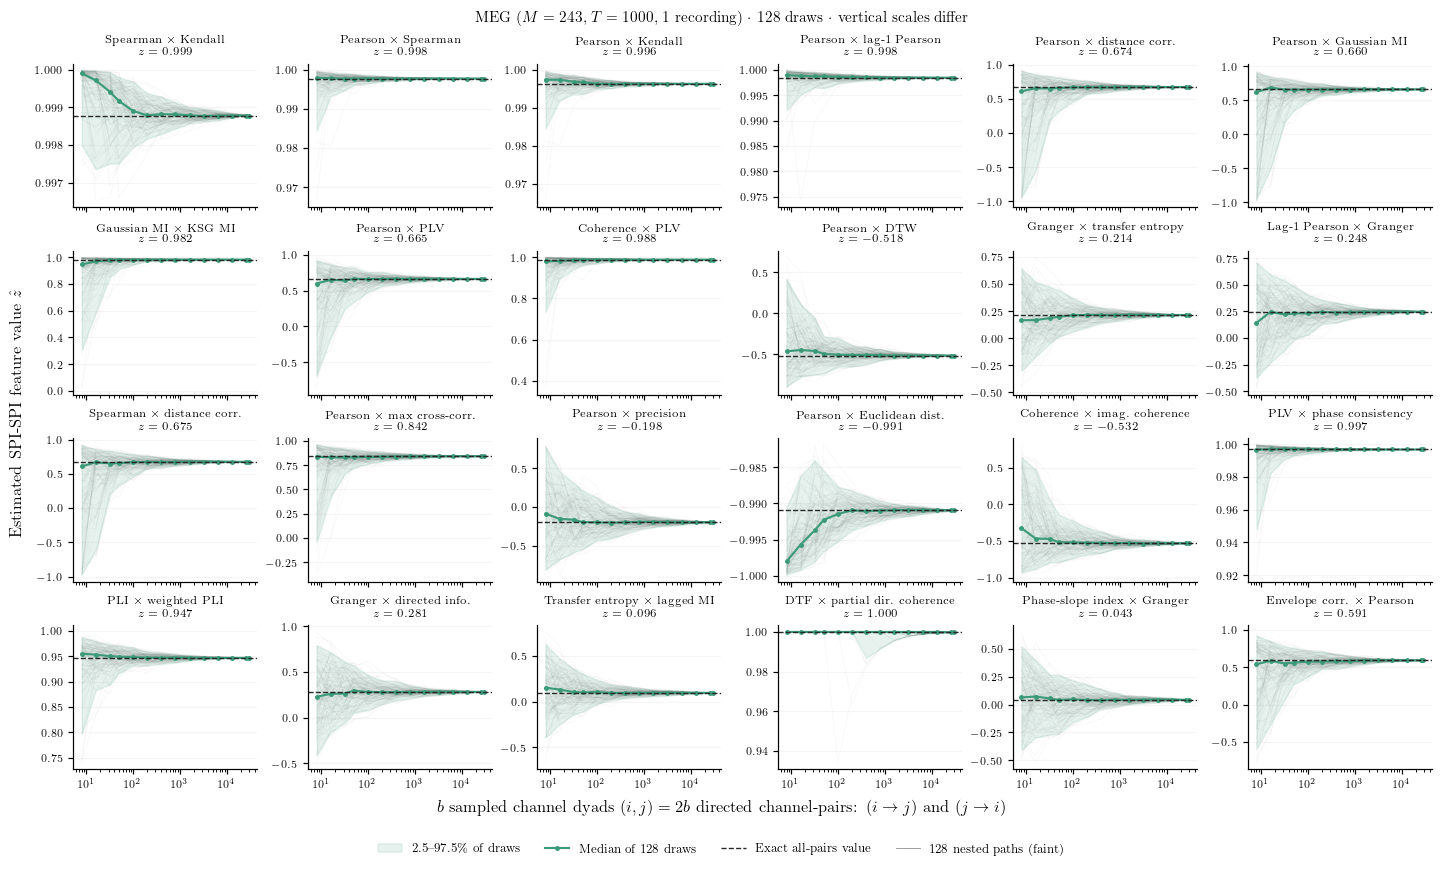

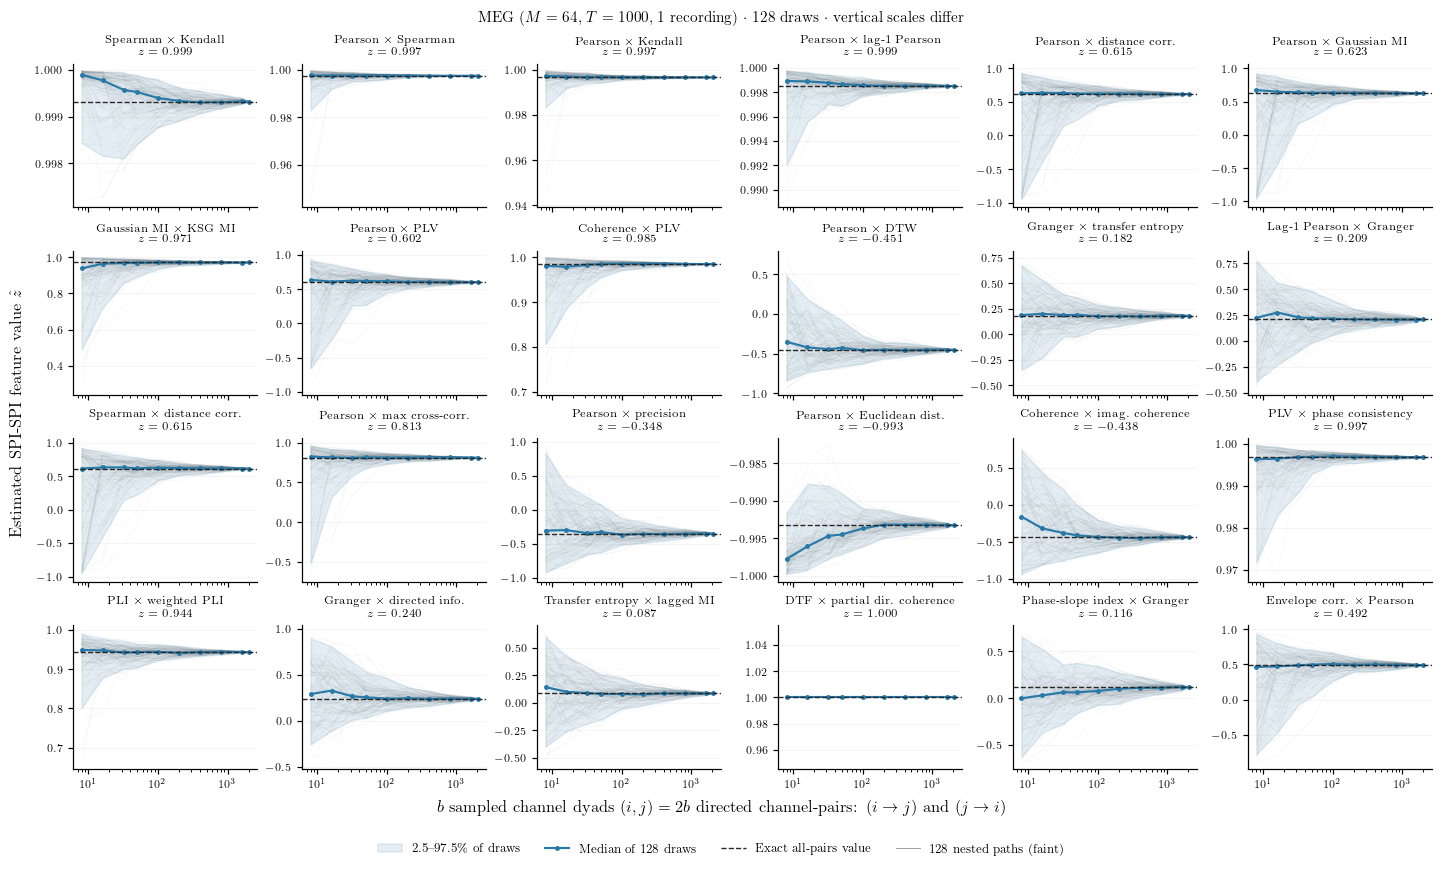

In [7]:
for M in (243, 64):
    V.gallery_figure(plt, RESULTS / f"gallery-meg-M{M}.npz", None, V.COLORS[M],
                     rf"MEG ($M={M}$, $T=1000$, 1 recording) $\cdot$ 128 draws $\cdot$ vertical scales differ")
    plt.show()

## 4. How many dyads

Sampling $b$ of $D$ dyads without replacement gives a root-mean-square error over coordinates of about

$$\mathrm{RMSE}(b) \approx c\,\sqrt{\frac{1 - b/D}{b}},$$

the standard error of a correlation from $b$ points with the finite-population correction. Left: medians (points) against that curve with one fitted $c$ per $M$. Right: the implied $c$ at each budget; it is flat, so one number per dataset describes the whole curve.

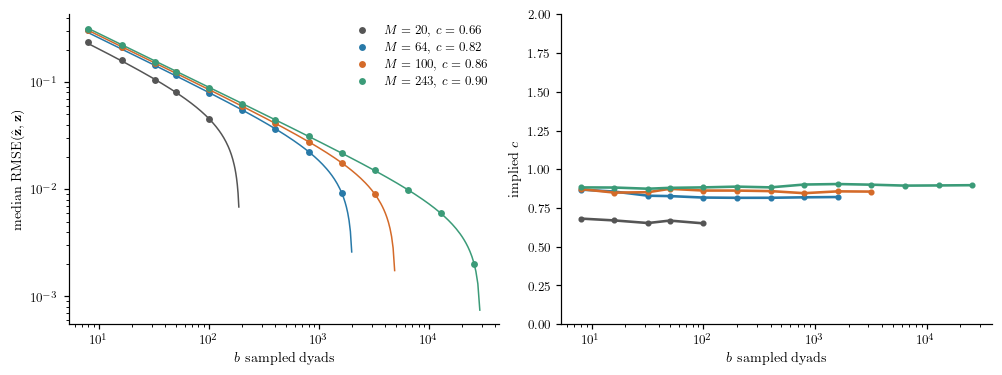

M,20,64,100,243
c,0.66,0.82,0.86,0.9


In [8]:
draws = pd.concat([local.assign(name="var"), meg])
med = draws.groupby(["M", "dyads"]).rmse.median().reset_index()
med["D"] = med.M * (med.M - 1) // 2
med = med[med.dyads < med.D]
med["c"] = med.rmse / np.sqrt((1 - med.dyads / med.D) / med.dyads)
c_hat = med[med.dyads >= 50].groupby("M").c.median()

fig, (a, b_) = plt.subplots(1, 2, figsize=(9, 3.3))
for M, part in med.groupby("M"):
    D = M * (M - 1) // 2
    grid = np.geomspace(8, D * .98, 200)
    a.plot(grid, c_hat[M] * np.sqrt((1 - grid / D) / grid), color=V.COLORS[M], lw=1)
    a.plot(part.dyads, part.rmse, "o", color=V.COLORS[M], ms=3.5, label=rf"$M={M}$, $c={c_hat[M]:.2f}$")
    b_.plot(part.dyads, part.c, "o-", color=V.COLORS[M], ms=3)
a.set(xscale="log", yscale="log", xlabel=r"$b$ sampled dyads", ylabel=r"median RMSE$(\hat{\mathbf{z}},\mathbf{z})$"); a.legend()
b_.set(xscale="log", xlabel=r"$b$ sampled dyads", ylabel=r"implied $c$", ylim=(0, 2))
plt.show()
c_hat.round(2).to_frame("c").T

Solving for the budget that meets a tolerance $\varepsilon$:

$$b(\varepsilon, D) = \left\lceil \frac{1}{(\varepsilon/c)^2 + 1/D} \right\rceil .$$

It never exceeds $D$, tends to $D$ for small recordings and to $(c/\varepsilon)^2$, independent of $M$, for large ones. $c$ is a property of the data: about 0.85–1.0 here and for densely coupled systems; sparse coupling in the companion study gave up to 1.8. Below, $\varepsilon = 0.03$ with the band spanning $c = 0.85$ to $1.8$ and the line at $c = 1.5$. Once the budget passes about half the census a sampled run costs as much as the full one, so the full table should be computed instead.

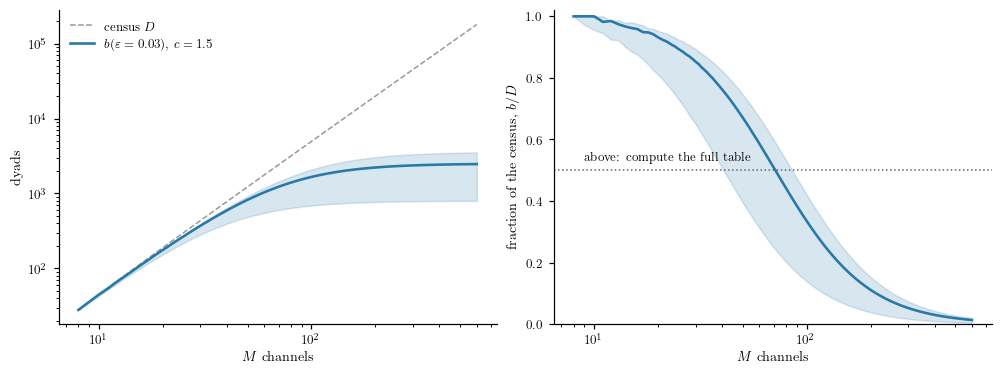

,M,D,"b, eps=0.05","b, eps=0.03","b, eps=0.02","b/D, eps=0.03"
0,20,190,157,177,184,0.93
1,32,496,320,414,456,0.83
2,64,2016,623,1117,1485,0.55
3,100,4950,762,1662,2633,0.34
4,150,11175,833,2043,3742,0.18
5,243,29403,874,2305,4722,0.08
6,500,124750,894,2451,5383,0.02


In [9]:
def pair_budget(M, tolerance, c=1.5):
    # Dyads needed for an RMSE of about `tolerance` in the SPI-SPI vector.
    D = M * (M - 1) // 2
    return min(D, int(np.ceil(1 / ((tolerance / c) ** 2 + 1 / D))))

Ms = np.unique(np.geomspace(8, 600, 120).astype(int))
D = Ms * (Ms - 1) // 2
budget = lambda c, eps=.03: np.array([pair_budget(M, eps, c) for M in Ms])
fig, (a, b_) = plt.subplots(1, 2, figsize=(9, 3.3))
a.plot(Ms, D, color=".6", ls="--", lw=1, label=r"census $D$")
a.fill_between(Ms, budget(.85), budget(1.8), color="#2879a8", alpha=.18)
a.plot(Ms, budget(1.5), color="#2879a8", label=r"$b(\varepsilon=0.03)$, $c=1.5$")
a.set(xscale="log", yscale="log", xlabel=r"$M$ channels", ylabel="dyads"); a.legend()
b_.fill_between(Ms, budget(.85) / D, budget(1.8) / D, color="#2879a8", alpha=.18)
b_.plot(Ms, budget(1.5) / D, color="#2879a8")
b_.axhline(.5, color=".4", ls=":", lw=1); b_.text(9, .53, "above: compute the full table", fontsize=8)
b_.set(xscale="log", xlabel=r"$M$ channels", ylabel=r"fraction of the census, $b/D$", ylim=(0, 1.02))
plt.show()

pd.DataFrame({"M": [20, 32, 64, 100, 150, 243, 500]}).assign(
    D=lambda f: f.M * (f.M - 1) // 2,
    **{rf"b, eps={e}": (lambda f, e=e: [pair_budget(M, e) for M in f.M]) for e in (.05, .03, .02)},
    **{"b/D, eps=0.03": lambda f: [round(pair_budget(M, .03) / (M * (M - 1) // 2), 2) for M in f.M]})

## 5. Cost

SPIs fall into three groups. *Pair loop*: evaluated only on the sampled dyads, bit-identical to the full table, cost proportional to $b/D$. *Pair-local*: the full table uses a vectorised path, the sampled run evaluates the pairs directly, equal to rounding. *Indexed*: computed on every channel and read off; cost does not fall. Measured on the $M=20$, $T=1000$ VAR(1) (means of three samples).

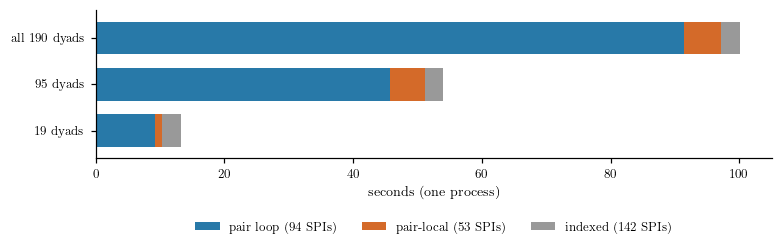

,pair loop (94 SPIs),pair-local (53 SPIs),indexed (142 SPIs),total,speedup
all 190 dyads,91.4,5.7,2.9,100.1,1.0
95 dyads,45.6,5.4,2.9,54.0,1.9
19 dyads,9.3,1.1,2.9,13.2,7.6


In [10]:
report = json.loads((RESULTS / "extraction.json").read_text())
rows = {"all 190 dyads": report["dense"]["by_tier"]}
for n in (95, 19):
    runs = [r["by_tier"] for r in report["sampled"] if r["n_pairs"] == n]
    rows[f"{n} dyads"] = {t: float(np.mean([r[t] for r in runs])) for t in V.TIERS}
cost = pd.DataFrame(rows).T[list(V.TIERS)]
cost.columns = [f"{t} ({report['tiers'][t]} SPIs)" for t in V.TIERS]
ax = cost.plot.barh(stacked=True, figsize=(7, 2.1), color=["#2879a8", "#d46a29", ".6"], width=.7)
ax.invert_yaxis(); ax.set_xlabel("seconds (one process)"); ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(.5, -.35))
plt.show()
cost.assign(total=cost.sum(1), speedup=lambda f: f.total.iloc[0] / f.total).round(1)

One MEG recording at $M=243$ ($D=29{,}403$) on Gadi, sampled, against its earlier full extraction.

In [11]:
if (GADI / "summary.json").exists():
    summary = json.loads((GADI / "summary.json").read_text())
    runs = pd.DataFrame(summary["runs"]).query("M == 243 and n_jobs == 1")
    display(runs[["run", "n_pairs", "wall_hours", "pbs_mem_gib", "failed"]].round(2))
    print(summary["m243_dense_reference"])
    print(summary["m243_vs_dense"])

,run,n_pairs,wall_hours,pbs_mem_gib,failed
0,m243-b1000-j1,1000.0,1.02,20.33,8


full extraction (r7, one core): 19.3 h, 8 failed SPIs

sampled entries against the r7 full extraction: 249 identical, 17 rounding, 15 changed in r8, 0 different, 8 failed in either